In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
df = pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,tested_positive
1,1,85,66,29,0,26.6,0.351,31,tested_negative
2,8,183,64,0,0,23.3,0.672,32,tested_positive
3,1,89,66,23,94,28.1,0.167,21,tested_negative
4,0,137,40,35,168,43.1,2.288,33,tested_positive


In [36]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [37]:
df = pd.get_dummies(df, columns=['Outcome'], drop_first=True, dtype=np.int64)
df = df.rename(columns={'Outcome_tested_positive': 'Outcome'})

In [38]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [39]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<Axes: xlabel='Pregnancies', ylabel='Age'>

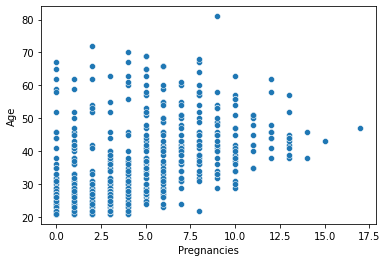

In [40]:
sns.scatterplot(x='Pregnancies', y='Age',data=df)

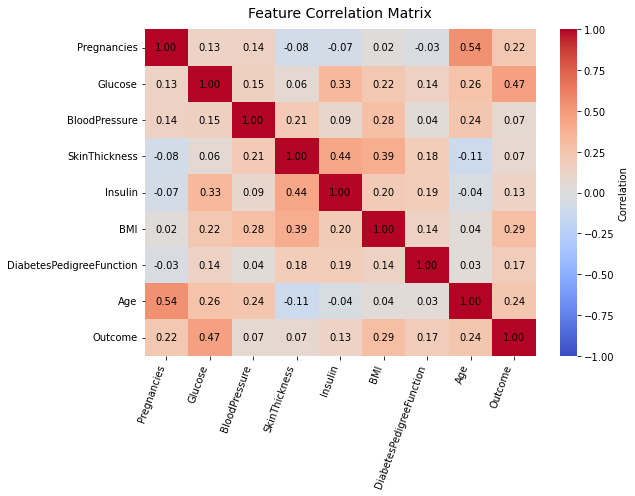

In [41]:
#Compute the Pearson correlation matrix
corr = df.corr()

#Configure and plot the heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr, 
    annot=True,                 # Display correlation coefficients
    fmt=".2f",                  # Format numbers to 2 decimal places
    cmap="coolwarm",              # Colormap matching the image (blue to red)
    vmin=-1.0, 
    vmax=1.0,                   # Range set from -1 to 1
    annot_kws={"color": "black"}, # Cell annotations in black font
    cbar_kws={'label': 'Correlation'}
)

#Styling to match the labels and orientation
plt.title("Feature Correlation Matrix", fontsize=14, pad=12)
plt.xticks(rotation=70, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

<Axes: xlabel='Age', ylabel='Glucose'>

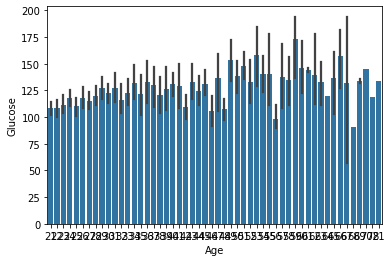

In [42]:
sns.barplot(x='Age', y='Glucose', data=df)

In [43]:
Q1 = df['Pregnancies'].quantile(0.25)
Q3 = df['Pregnancies'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['Pregnancies'] >= lower_bound) & (df['Pregnancies'] <= upper_bound)]


In [44]:
Q1 = df['Glucose'].quantile(0.25)
Q3 = df['Glucose'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['Glucose'] >= lower_bound) & (df['Glucose'] <= upper_bound)]


In [45]:
Q1 = df['BloodPressure'].quantile(0.25)
Q3 = df['BloodPressure'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['BloodPressure'] >= lower_bound) & (df['BloodPressure'] <= upper_bound)]


In [46]:
Q1 = df['SkinThickness'].quantile(0.25)
Q3 = df['SkinThickness'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['SkinThickness'] >= lower_bound) & (df['SkinThickness'] <= upper_bound)]


In [47]:
Q1 = df['Insulin'].quantile(0.25)
Q3 = df['Insulin'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['Insulin'] >= lower_bound) & (df['Insulin'] <= upper_bound)]


In [48]:
Q1 = df['BMI'].quantile(0.25)
Q3 = df['BMI'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['BMI'] >= lower_bound) & (df['BMI'] <= upper_bound)]


In [49]:
Q1 = df['DiabetesPedigreeFunction'].quantile(0.25)
Q3 = df['DiabetesPedigreeFunction'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['DiabetesPedigreeFunction'] >= lower_bound) & (df['DiabetesPedigreeFunction'] <= upper_bound)]


In [50]:
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
df = df[(df['Age'] >= lower_bound) & (df['Age'] <= upper_bound)]


<Axes: xlabel='Pregnancies', ylabel='Age'>

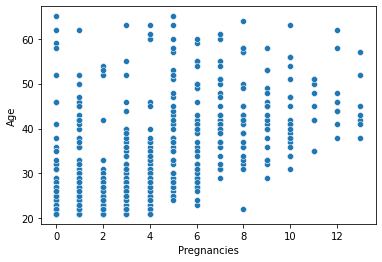

In [51]:
sns.scatterplot(data=df, x='Pregnancies', y='Age')

In [52]:
#zero value not NaN
zero_missing_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
print("Zero counts prior to cleaning:")
print((df[zero_missing_cols] == 0).sum())

# Replace biological 0s with NaN
df_cleaned = df.copy()
df_cleaned[zero_missing_cols] = df_cleaned[zero_missing_cols].replace(0, np.nan)

Zero counts prior to cleaning:
Glucose            0
BloodPressure      0
SkinThickness    173
Insulin          300
BMI                0
dtype: int64


In [53]:
df_cleaned.isnull().sum()

Pregnancies                   0
Glucose                       0
BloodPressure                 0
SkinThickness               173
Insulin                     300
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [54]:
df_cleaned['Insulin'] = df_cleaned['Insulin'].fillna(df_cleaned['Insulin'].median())
df_cleaned['SkinThickness'] = df_cleaned['SkinThickness'].fillna(df_cleaned['SkinThickness'].median())

In [63]:
df_cleaned.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [55]:
#split data in 80:20 ratio
X = df_cleaned.drop(columns=['Outcome'])
y = df_cleaned['Outcome']
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"\nTraining set size: {X_train.shape[0]} samples")
print(f"Testing set size:  {X_test.shape[0]} samples")
print(f"Positive class ratio (train): {y_train.mean():.2%}")


Training set size: 508 samples
Testing set size:  128 samples
Positive class ratio (train): 30.91%


In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

candidate_models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    "Gaussian Naive Bayes": GaussianNB(),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Support Vector Machine": SVC(probability=True, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, class_weight='balanced', random_state=42)
}

scoring_metrics = ['recall', 'precision', 'f1', 'roc_auc', 'average_precision']
benchmark_results = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [57]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
for name, clf in candidate_models.items():
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', clf)
    ])
    
    cv_scores = cross_validate(pipeline, X_train, y_train, cv=skf, scoring=scoring_metrics)
    
    benchmark_results.append({
        'Model': name,
        'Mean Recall': cv_scores['test_recall'].mean(),
        'Mean Precision': cv_scores['test_precision'].mean(),
        'Mean F1': cv_scores['test_f1'].mean(),
        'Mean ROC-AUC': cv_scores['test_roc_auc'].mean(),
        'Mean PR-AUC': cv_scores['test_average_precision'].mean()
    })

results_df = pd.DataFrame(benchmark_results).sort_values(by='Mean Recall', ascending=False)
print("\n=== 5-Fold Stratified CV Benchmark Results ===")
print(results_df.to_string(index=False))


=== 5-Fold Stratified CV Benchmark Results ===
                 Model  Mean Recall  Mean Precision  Mean F1  Mean ROC-AUC  Mean PR-AUC
Support Vector Machine     0.753024        0.588083 0.657546      0.831603     0.660041
   Logistic Regression     0.713710        0.576819 0.635605      0.834762     0.696380
  Gaussian Naive Bayes     0.585887        0.634045 0.604361      0.816965     0.671874
         Random Forest     0.529234        0.687218 0.594755      0.842114     0.709130
   K-Nearest Neighbors     0.471774        0.590662 0.519691      0.779554     0.584488


In [58]:
#hyper parameter tuning using random forest 
rf_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))
])

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [4, 6, 8, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf_pipe,
    param_grid=param_grid,
    cv=skf,
    scoring='roc_auc',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_pipeline = grid_search.best_estimator_
print(f"\nBest Hyperparameters: {grid_search.best_params_}")


Best Hyperparameters: {'classifier__max_depth': 6, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}


In [59]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

print("\n=== Final Test Set Evaluation ===")
print(classification_report(y_test, y_pred, target_names=['Non-Diabetic (0)', 'Diabetic (1)']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_pred_proba):.4f}")
print(f"Test PR-AUC:  {average_precision_score(y_test, y_pred_proba):.4f}")


=== Final Test Set Evaluation ===
                  precision    recall  f1-score   support

Non-Diabetic (0)       0.87      0.78      0.83        88
    Diabetic (1)       0.61      0.75      0.67        40

        accuracy                           0.77       128
       macro avg       0.74      0.77      0.75       128
    weighted avg       0.79      0.77      0.78       128

Confusion Matrix:
[[69 19]
 [10 30]]
Test ROC-AUC: 0.8423
Test PR-AUC:  0.7235


In [60]:
# Export Model Artifact & Production Inference
import joblib
MODEL_PATH = "diabetes_model_pipeline.joblib"
joblib.dump(best_pipeline, MODEL_PATH)
print(f"\nPipeline successfully serialized and saved to '{MODEL_PATH}'.")

# Inference Example
loaded_pipeline = joblib.load(MODEL_PATH)
sample_patient = pd.DataFrame([{
    'Pregnancies': 2,
    'Glucose': 148,
    'BloodPressure': 72,
    'SkinThickness': 35,
    'Insulin': 0,      # Will be converted to NaN and imputed automatically
    'BMI': 33.6,
    'DiabetesPedigreeFunction': 0.627,
    'Age': 50
}])
sample_patient[zero_missing_cols] = sample_patient[zero_missing_cols].replace(0, np.nan)

pred = loaded_pipeline.predict(sample_patient)[0]
prob = loaded_pipeline.predict_proba(sample_patient)[0, 1]
print(f"\nSample Patient Prediction: {'Diabetic' if pred == 1 else 'Non-Diabetic'} (Risk Probability: {prob:.2%})")


Pipeline successfully serialized and saved to 'diabetes_model_pipeline.joblib'.

Sample Patient Prediction: Diabetic (Risk Probability: 78.63%)


In [61]:
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix

knn_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier())
]).fit(X_train, y_train)

y_pred_knn = knn_pipeline.predict(X_test)
y_prob_knn = knn_pipeline.predict_proba(X_test)[:, 1]
tn_knn, fp_knn, fn_knn, tp_knn = confusion_matrix(y_test, y_pred_knn).ravel()

print("KNN Task-Specific Metrics:")
print(f"Recall (Sensitivity): {recall_score(y_test, y_pred_knn):.4f}")
print(f"Specificity:          {tn_knn / (tn_knn + fp_knn):.4f}")
print(f"Precision:            {precision_score(y_test, y_pred_knn):.4f}")
print(f"F1-Score:             {f1_score(y_test, y_pred_knn):.4f}")
print(f"ROC-AUC:              {roc_auc_score(y_test, y_prob_knn):.4f}")
print(f"PR-AUC:               {average_precision_score(y_test, y_prob_knn):.4f}")
print(f"Brier Score:          {brier_score_loss(y_test, y_prob_knn):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))


KNN Task-Specific Metrics:
Recall (Sensitivity): 0.5250
Specificity:          0.8182
Precision:            0.5676
F1-Score:             0.5455
ROC-AUC:              0.7547
PR-AUC:               0.5373
Brier Score:          0.1866
Confusion Matrix:
 [[72 16]
 [19 21]]


In [62]:
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix

y_pred_rf = best_pipeline.predict(X_test)
y_prob_rf = best_pipeline.predict_proba(X_test)[:, 1]
tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(y_test, y_pred_rf).ravel()

print("Random Forest Task-Specific Metrics:")
print(f"Recall (Sensitivity): {recall_score(y_test, y_pred_rf):.4f}")
print(f"Specificity:          {tn_rf / (tn_rf + fp_rf):.4f}")
print(f"Precision:            {precision_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score:             {f1_score(y_test, y_pred_rf):.4f}")
print(f"ROC-AUC:              {roc_auc_score(y_test, y_prob_rf):.4f}")
print(f"PR-AUC:               {average_precision_score(y_test, y_prob_rf):.4f}")
print(f"Brier Score:          {brier_score_loss(y_test, y_prob_rf):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))


Random Forest Task-Specific Metrics:
Recall (Sensitivity): 0.7500
Specificity:          0.7841
Precision:            0.6122
F1-Score:             0.6742
ROC-AUC:              0.8423
PR-AUC:               0.7235
Brier Score:          0.1549
Confusion Matrix:
 [[69 19]
 [10 30]]
